In [1]:
# Import the libraries needed to load BrainVision EEG recordings, compute event-related responses, manipulate numerical arrays, and visualize scalp topographies and projected signals. All analysis functions rely on these imports.
# %pip install mne
import pandas as pd
import numpy as np
import mne
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [2]:
# Set all fifteen run-level parameters in one place before loading data or calling analysis functions. Sampling frequency is intentionally unresolved here and will be read from the EEG header.

# Input and filtering
eeg_file = "Smits11.vhdr"
low_freq = 1.0
high_freq = None

# Recording frequency: populated from raw.info after loading, never hard-coded
sfreq = None

# Epoch and baseline windows, in milliseconds relative to the event
epoch_pre_ms = 20
epoch_post_ms = 100
baseline_start_ms = 11
baseline_end_ms = 14
min_trigger_distance = 100  # samples; preserve original strict > comparison

# Selected scalp map: one time point only, in milliseconds
erp_time = 18.0
normalize_erp = True

# Figure settings
n_cols = 1                 # retained configuration; single-map mode only
cmap = "jet"
save_figures = True
plot_all_topographies = False  # retained configuration; grid plotting is disabled

In [3]:
def read_prep_eeg(eeg_file_path_vhdr, low_freq=None, high_freq=None):
    """Load BrainVision data, classify auxiliary channels and retain EEG channels."""
    raw = mne.io.read_raw_brainvision(eeg_file_path_vhdr, preload=True)
    auxiliary_types = {"Mano DX": "misc", "Mano SX": "misc", "ECG": "ecg", "pressione": "misc"}
    raw.set_channel_types({name: kind for name, kind in auxiliary_types.items() if name in raw.ch_names})
    if low_freq is not None or high_freq is not None:
        raw = raw.copy().filter(l_freq=low_freq, h_freq=high_freq)
    return raw.pick("eeg")

In [4]:
def get_erp(raw, epoch_pre_ms, epoch_post_ms, baseline_start_ms,
            baseline_end_ms, min_trigger_distance):
    """Average event-aligned EEG epochs and remove the original post-trigger baseline."""
    sfreq = float(raw.info["sfreq"])
    pre = int((epoch_pre_ms / 1000.0) * sfreq)
    post = int((epoch_post_ms / 1000.0) * sfreq)
    if pre < 0 or post <= 0:
        raise ValueError("Epoch durations must satisfy pre >= 0 and post > 0.")

    events, _ = mne.events_from_annotations(raw)
    if len(events) == 0:
        raise ValueError("No annotated events found in the EEG recording.")
    samples = events[:, 0]
    clean = [samples[0]]
    for sample in samples[1:]:
        if sample - clean[-1] > min_trigger_distance:
            clean.append(sample)

    epochs = []
    for trigger in clean:
        if trigger - pre < 0 or trigger + post > raw.n_times:
            continue
        epoch, _ = raw[:, trigger - pre:trigger + post]
        epochs.append(epoch)
    if not epochs:
        raise ValueError("No complete epochs remain after trigger filtering.")

    erp = np.mean(np.stack(epochs, axis=0), axis=0)
    b_start = pre + int((baseline_start_ms / 1000.0) * sfreq)
    b_end = pre + int((baseline_end_ms / 1000.0) * sfreq)
    if not (0 <= b_start < b_end <= erp.shape[1]):
        raise ValueError("Baseline interval must lie inside the ERP epoch.")
    baseline = np.mean(erp[:, b_start:b_end], axis=1, keepdims=True)
    time_epoch = np.arange(-pre, post) / sfreq
    return erp - baseline, time_epoch

In [5]:
def compute_A(erp_mean, time_epoch, erp_time, normalize=True):
    """Extract the ERP vector at the nearest real sample and optionally normalize it."""
    requested_seconds = erp_time / 1000.0
    if requested_seconds < time_epoch[0] or requested_seconds > time_epoch[-1]:
        raise ValueError(f"erp_time={erp_time} ms is outside the epoch time range.")
    index = int(np.argmin(np.abs(time_epoch - requested_seconds)))
    actual_time_ms = float(time_epoch[index] * 1000.0)
    potential = np.asarray(erp_mean[:, index], dtype=float).copy()
    if normalize:
        denominator = potential.sum()
        if np.isclose(denominator, 0.0, atol=1e-15, rtol=0):
            raise ValueError("Cannot normalize A: ERP electrode values sum to (nearly) zero.")
        A = potential / denominator  # preserve original sum-normalization
    else:
        A = potential.copy()
    return A, potential, actual_time_ms

In [6]:
def compute_W(A):
    """Compute Moore-Penrose pseudoinverse of a single topographic row vector."""
    A = np.asarray(A, dtype=float).reshape(-1)
    if not np.any(A):
        raise ValueError("Cannot compute useful W from an all-zero A vector.")
    return np.linalg.pinv(A.reshape(1, -1)).reshape(-1)

In [7]:
def plot_topography(raw, values, time_ms, title_prefix="A", cmap="jet",
                    save_path=None, dpi=300):
    """Plot exactly one 2D scalp map; do not calculate or normalize its values."""
    values = np.asarray(values, dtype=float).reshape(-1)
    info = raw.info.copy()
    picks = mne.pick_types(info, eeg=True)
    info = mne.pick_info(info, picks)
    if values.size != len(info.ch_names):
        raise ValueError(f"Map has {values.size} values but EEG has {len(info.ch_names)} channels.")
    montage = mne.channels.make_standard_montage("standard_1020")
    info.set_montage(montage, on_missing="ignore")

    fig, ax = plt.subplots(figsize=(6, 5))
    im, _ = mne.viz.plot_topomap(values, info, axes=ax, show=False, cmap=cmap)
    ax.set_title(f"{title_prefix} - {time_ms:.1f} ms")
    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=dpi, bbox_inches="tight")
    plt.show()
    return fig, ax

In [8]:
# Load and filter the EEG recording, then obtain its actual sampling frequency from the BrainVision header. Epoch dimensions will be computed from this metadata rather than assuming 5000 Hz.
if plot_all_topographies or n_cols != 1:
    raise ValueError("This notebook is configured for exactly one topography; use plot_all_topographies=False and n_cols=1.")
raw = read_prep_eeg(eeg_file, low_freq=low_freq, high_freq=high_freq)
sfreq = float(raw.info["sfreq"])
print(f"EEG sampling frequency: {sfreq:g} Hz")
print(f"EEG channels: {len(raw.ch_names)}")

Extracting parameters from Smits11.vhdr...
Setting channel info structure...
Reading 0 ... 1524799  =      0.000 ...   304.960 secs...
Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Filter length: 16501 samples (3.300 s)

EEG sampling frequency: 5000 Hz
EEG channels: 63


In [9]:
# Average event-aligned epochs while preserving the original duplicate-trigger criterion and post-stimulus baseline correction. The function returns both the corrected ERP matrix and its correctly sampled time axis.
erp_mean, time_epoch = get_erp(
    raw, epoch_pre_ms, epoch_post_ms, baseline_start_ms,
    baseline_end_ms, min_trigger_distance
)
print("ERP matrix shape:", erp_mean.shape)
print("ERP time range (ms):", time_epoch[0] * 1000, "to", time_epoch[-1] * 1000)

Used Annotations descriptions: [np.str_('Response/R  7'), np.str_('Response/R 15')]
ERP matrix shape: (63, 600)
ERP time range (ms): -20.0 to 99.8


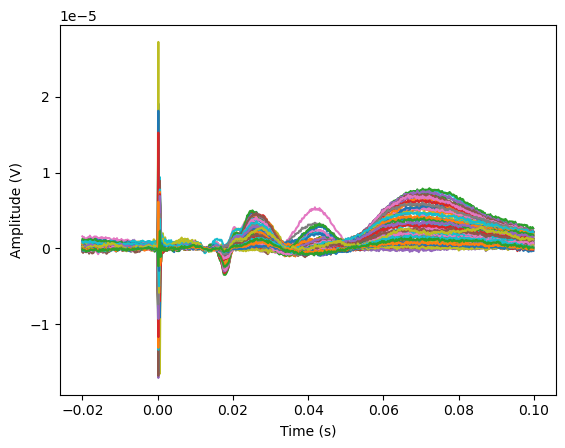

In [10]:
# Plot the ERP waveforms for every retained EEG channel against the common event-relative time axis. This time-course plot is distinct from the single scalp topography requested below.
for i in range(erp_mean.shape[0]):
    plt.plot(time_epoch, erp_mean[i])
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (V)")
plt.show()

In [11]:
# Calculate A exclusively from the requested ERP time and channel potentials, without rendering graphics. Select the nearest recorded sample and preserve the original optional sum-based normalization operation.
A, A_raw, actual_erp_time = compute_A(erp_mean, time_epoch, erp_time, normalize=normalize_erp)
print(f"Requested ERP time: {erp_time:.3f} ms; selected sample: {actual_erp_time:.3f} ms")
print("A shape:", A.shape)

Requested ERP time: 18.000 ms; selected sample: 18.000 ms
A shape: (63,)


In [12]:
# Calculate W from the selected A vector using a separate mathematical function, independent of plotting. This preserves the notebook's Moore-Penrose pseudoinverse and yields one spatial coefficient per EEG channel.
W = compute_W(A)
print("W shape:", W.shape)

W shape: (63,)


In [13]:
# Display the selected A and W coefficient arrays for numerical inspection. Both vectors refer to the same sampled ERP time and are computed before either topographic figure is created.
print("A:", A)
print("W:", W)

A: [ 0.00157138 -0.00494373  0.00971678  0.00812402  0.00669226 -0.00331427
  0.01852409  0.02457632  0.00959386  0.04699833  0.03909814  0.038642
  0.04993158  0.02962017  0.02290245  0.0156126   0.01336378  0.02340613
  0.00875814 -0.00516963  0.01521425  0.02720461  0.01634689  0.01341603
  0.0007393   0.00734625  0.01205697  0.00785634  0.00435601  0.00535213
  0.00158979  0.00391929  0.00090106  0.00221909 -0.00622617  0.00112667
  0.01593956 -0.0059142   0.00127036  0.01737208  0.03314878  0.02210969
  0.0510767   0.04615506  0.04395642  0.03203874  0.04283552  0.03398766
  0.02285488  0.01042177  0.01649696  0.02802263  0.03533017  0.01974134
  0.00584266  0.01157627  0.01692668  0.01099636  0.00311229  0.00466194
  0.00434335  0.00325202  0.00532141]
W: [ 0.05214923 -0.16406748  0.32247041  0.26961136  0.22209578 -0.10999058
  0.614758    0.81561314  0.31839104  1.55973154  1.2975482   1.28241017
  1.65707693  0.98300326  0.76006241  0.51813449  0.44350314  0.77677816
  0.29065

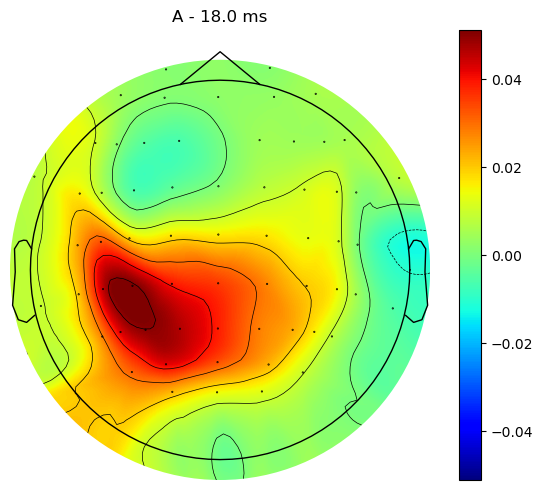

In [14]:
# Render exactly one scalp topography of the computed A vector at erp_time. Plotting uses existing data only and optionally writes the figure to A.png without changing A.
fig_A, ax_A = plot_topography(raw, A, actual_erp_time, title_prefix="A", cmap=cmap,
                              save_path="A.png" if save_figures else None)

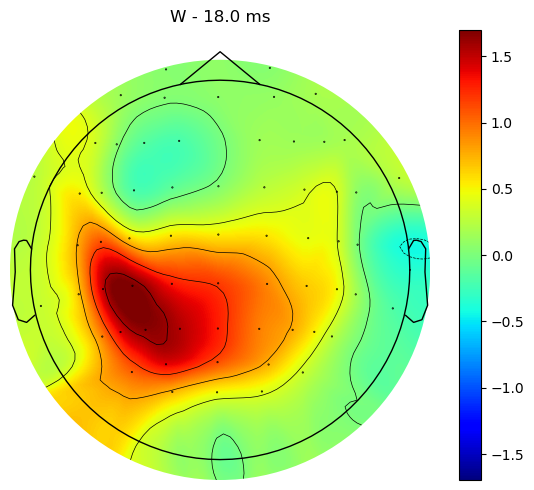

In [15]:
# Render exactly one scalp topography of the pseudoinverse W at the same ERP sample. This separate display operation does not recompute A, modify W, or create a grid.
fig_W, ax_W = plot_topography(raw, W, actual_erp_time, title_prefix="W", cmap=cmap,
                              save_path="W.png" if save_figures else None)

In [16]:
# Project the complete filtered EEG recording onto the single spatial weight vector W. Check that the electrode counts match before producing the continuous one-dimensional FSResult signal.
eeg_data = raw.get_data()
if W.size != eeg_data.shape[0]:
    raise ValueError("W and the EEG data must have the same number of channels.")
FSResult = W @ eeg_data
print("Dimensions W:", W.shape)
print("Dimensions EEG:", eeg_data.shape)
print("Dimensions FSResult:", FSResult.shape)

Dimensions W: (63,)
Dimensions EEG: (63, 1524800)
Dimensions FSResult: (1524800,)


In [17]:
# Display the numerical FSResult vector generated by applying W to the complete EEG recording. Its length corresponds to the number of acquired time samples, not the ERP epoch length.
FSResult

array([-4.55067159e-17, -1.11697137e-04, -2.47555764e-05, ...,
       -5.59760687e-05,  1.05042211e-04, -2.30942161e-17])

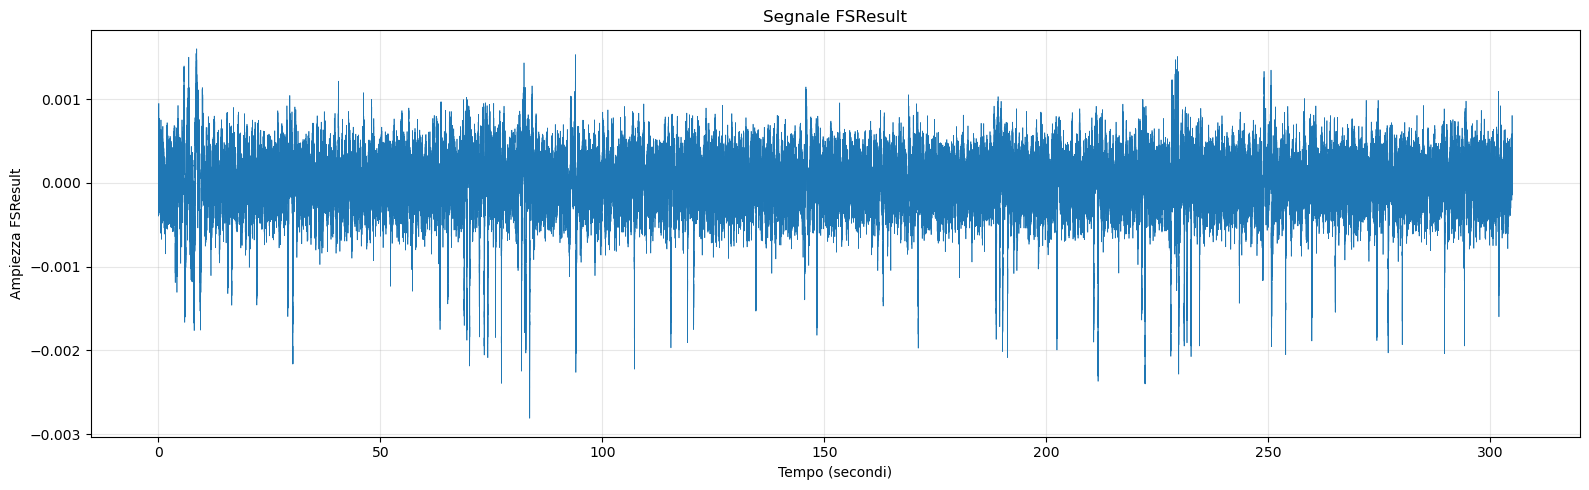

In [18]:
# Draw the full projected signal FSResult against recording time using the sampling frequency read from the EEG header. This is a temporal signal plot, not a scalp topography grid.
time = np.arange(FSResult.size) / sfreq
plt.figure(figsize=(16, 5))
plt.plot(time, FSResult, linewidth=0.5)
plt.title("Segnale FSResult")
plt.xlabel("Tempo (secondi)")
plt.ylabel("Ampiezza FSResult")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
# Compare the selected normalized ERP vector A with its pseudoinverse weights W. Print their componentwise difference and Euclidean distance to retain the original notebook's final numerical comparison.
diff_A_W = A - W
distanza = np.linalg.norm(diff_A_W)
print("Differenza elemento per elemento:", diff_A_W)
print("Distanza euclidea:", distanza)

Differenza elemento per elemento: [-0.05057785  0.15912375 -0.31275363 -0.26148734 -0.21540352  0.10667631
 -0.59623391 -0.79103682 -0.30879718 -1.51273321 -1.25845006 -1.24376817
 -1.60714535 -0.95338309 -0.73715997 -0.5025219  -0.43013936 -0.75337203
 -0.28189772  0.16639474 -0.48970028 -0.87563341 -0.52615655 -0.43182128
 -0.0237957  -0.23645345 -0.38807705 -0.25287179 -0.14020673 -0.17226868
 -0.05117065 -0.12615012 -0.0290024  -0.07142588  0.20040151 -0.036264
 -0.51304589  0.19035999 -0.04088892 -0.55915433 -1.06695818 -0.7116437
 -1.64400334 -1.48559086 -1.41482329 -1.03122944 -1.37874494 -1.09395937
 -0.73562908 -0.33544487 -0.53098675 -0.90196322 -1.13717046 -0.63541374
 -0.18805746 -0.37260501 -0.5448183  -0.35393945 -0.10017515 -0.1500536
 -0.1397993  -0.10467251 -0.1712799 ]
Distanza euclidea: 5.587225268039541
